In [1]:
#from PIL import Image
import cv2
import matplotlib.pyplot as plt
import sys
#from skimage import io
from pathlib import Path
from skimage.color import rgb2gray
from skimage.filters import gaussian
from skimage.segmentation import active_contour
import numpy as np
from scipy.signal import savgol_filter


In [2]:
CHANNEL = Path(r"F:\Luca_Data\20250918_cellTHP1Paolo_test1\20250918_CellTHP1_100w_60h_08muls_chirp\constriction7\constriction7011809.tif")
#CHANNEL = Path("/Volumes/Elements/Rheoflu/Luca/20260925_test_microscope_and_camera/fluoromax_0.25_1000fps_1uls/fluoromax_0.25_1000fps_1uls000001.tif")
#CHANNEL = Path("/Users/lucaasinari/Desktop/piv/fluoromax_0.25_1000fps_1uls000001.tif")
OUTPUT_DIR = Path("results/stress_from_channel")
PATTERN = "*.tif"  

pixel_size_um = 3.28
eta = 0.001  # Pa.s
q = 0.0001  # m^3/s

# **CUT**

We cut the image to see only the channel

image: <class 'numpy.ndarray'> uint8 (256, 256)
cropped: <class 'numpy.ndarray'> uint8 (256, 145)


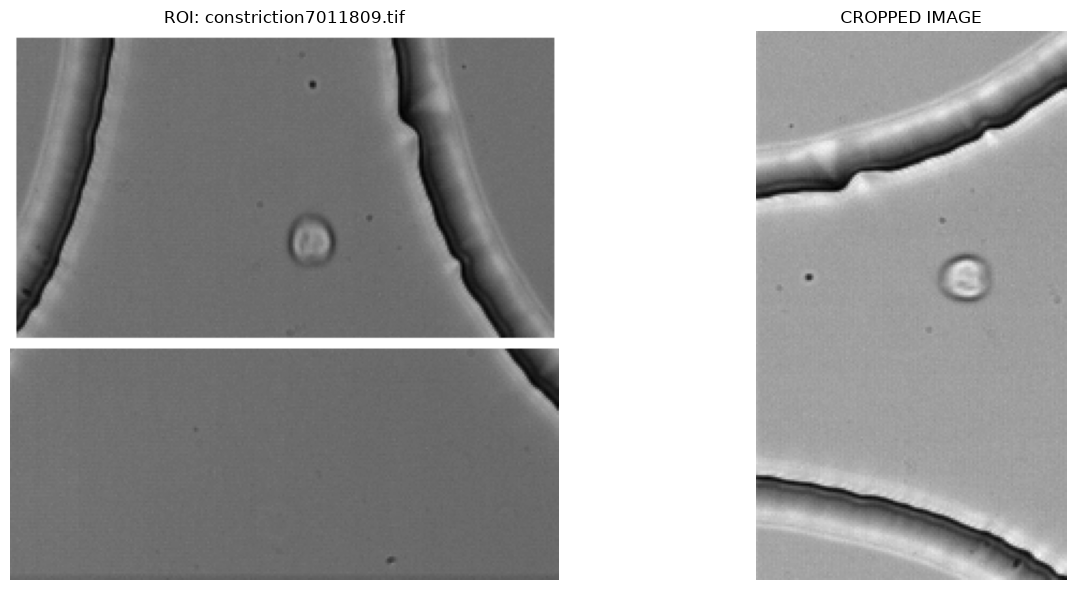

In [3]:
# Parametri di ritaglio (Crop)
# Ritaglia l'immagine per alleggerire l'analisi. Regola questi valori in base alla tua ROI.
CROP_Y_MIN = 0
CROP_Y_MAX = 145
CROP_X_MIN = 0
CROP_X_MAX = 256

if not CHANNEL:
    raise FileNotFoundError(f"No image founf in {CHANNEL} as {PATTERN}")

# Legge l'immagine in scala di grigi.
image = cv2.imread(str(CHANNEL), cv2.IMREAD_GRAYSCALE)
if image is None:
    raise ValueError(f"Impossibile to read the image: {CHANNEL}")

# Estrae la regione di interesse.
cropped = image[CROP_Y_MIN:CROP_Y_MAX, CROP_X_MIN:CROP_X_MAX]
cropped = cv2.rotate(cropped, cv2.ROTATE_90_COUNTERCLOCKWISE)  # Ruota di 90 gradi in senso antiorario

# Crea una copia per disegnare il rettangolo senza modificare l'immagine originale.
image_with_rectangle = image.copy()
cv2.rectangle(
    image_with_rectangle,
    (CROP_X_MIN, CROP_Y_MIN),  # Angolo in alto a sinistra: (x, y)
    (CROP_X_MAX, CROP_Y_MAX),  # Angolo in basso a destra: (x, y)
    color=255,                 # Bianco, dato che l'immagine è in scala di grigi
    thickness=3,
)


# Visualizza l'immagine originale con il rettangolo e, a fianco, il ritaglio.
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(image_with_rectangle, cmap="gray")
axes[0].set_title(f"ROI: {CHANNEL.name}")
axes[0].axis("off")

print("image:", type(image), image.dtype, image.shape)
print("cropped:", type(cropped), getattr(cropped, "dtype", None),
      getattr(cropped, "shape", None))

axes[1].imshow(cropped, cmap="gray")
axes[1].set_title("CROPPED IMAGE")
axes[1].axis("off")

plt.tight_layout()
plt.show()

**Edge finding**

We find the edge of the channel using active contour

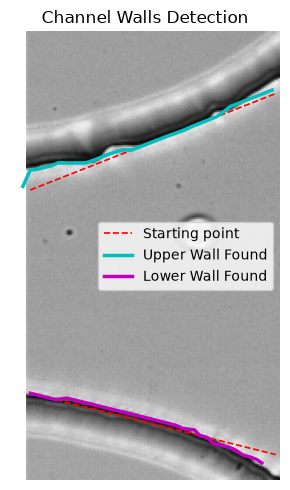

In [4]:
# 1. Dimensioni dell'immagine ritagliata e ruotata
H, W = cropped.shape

# 2. Creiamo le coordinate x lungo tutta la larghezza dell'immagine
n_punti = 30
x_coords = np.linspace(2, W - 3, n_punti)

# --- LINEA SUPERIORE INIZIALE (vicino al bordo in alto) ---
y_start_top = 90  # y all'estremità sinistra
y_end_top = 35    # y all'estremità destra
y_top_init = np.linspace(y_start_top, y_end_top, len(x_coords))
init_top = np.column_stack([y_top_init, x_coords])

# --- LINEA INFERIORE INIZIALE (vicino al bordo in basso) ---
y_start_bottom = H - 50  # y all'estremità sinistra
y_end_bottom = H - 15   # y all'estremità destra
y_bottom_init = np.linspace(y_start_bottom, y_end_bottom, len(x_coords))
init_bottom = np.column_stack([y_bottom_init, x_coords])

# 3. Sfocatura gaussiana dell'immagine per eliminare rumore / particelle
blurred = gaussian(cropped, sigma=2)

snake_params = {
    "alpha": 0.03,  # Elasticità: spinge la curva a contrarsi (valori tipici: 0.01 - 0.1)
    "beta": 0.5,   # Rigidità: mantiene la curva morbida e senza spigoli (valori tipici: 1 - 100)
    "w_edge": 50.0,  # Attrazione per i bordi: 1.0 significa che cerca bordi netti
    "w_line": 0.0,  # Settato a 0 perché cerchiamo un "bordo" (cambio di colore), non una linea
    "boundary_condition": "free",  # oppure "fixed"
    "max_num_iter": 2500,
}

snake_top = active_contour(blurred, init_top, **snake_params)
snake_bottom = active_contour(blurred, init_bottom, **snake_params)

# 6. Visualizzazione delle due pareti
fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(cropped, cmap="gray", origin="upper", aspect="equal")

# Linee iniziali (rosse tratteggiate)
ax.plot(init_top[:, 1], init_top[:, 0], "--r", lw=1.2, label="Starting point")
ax.plot(init_bottom[:, 1], init_bottom[:, 0], "--r", lw=1.2)

# Pareti trovate
ax.plot(
    snake_top[:, 1],
    snake_top[:, 0],
    "-c",
    lw=2.5,
    label="Upper Wall Found",
)
ax.plot(
    snake_bottom[:, 1],
    snake_bottom[:, 0],
    "-m",
    lw=2.5,
    label="Lower Wall Found",
)

ax.set_title("Channel Walls Detection")
ax.legend(loc="center right", fontsize=10)
ax.axis("off")

plt.tight_layout()
plt.show()


# **Channel width**

We evaluate the channel width $L(x)$ using the obtained contours.

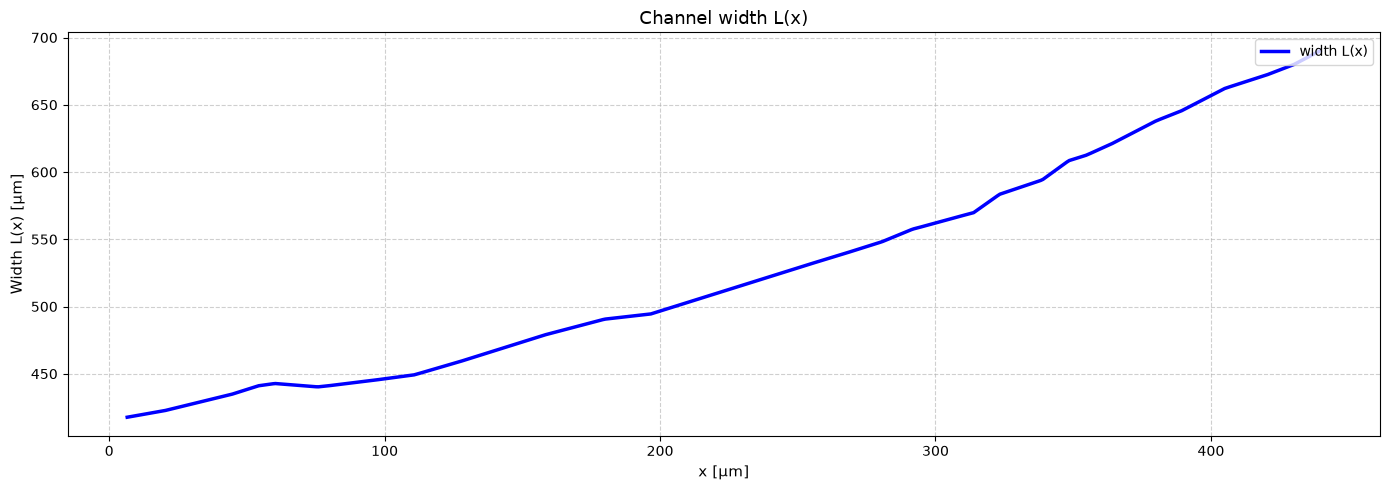

In [16]:
# ==========================================
# 6. FUNZIONE PER L'width DEL CANALE L(x)
# ==========================================
def compute_channel_height(snake_top, snake_bottom, num_points=500):
    """Calcola la larghezza locale L(x) e la larghezza media del canale."""
    y_top, x_top = snake_top[:, 0], snake_top[:, 1]
    y_bottom, x_bottom = snake_bottom[:, 0], snake_bottom[:, 1]

    sort_top = np.argsort(x_top)
    x_top_s, y_top_s = x_top[sort_top], y_top[sort_top]

    sort_bot = np.argsort(x_bottom)
    x_bot_s, y_bot_s = x_bottom[sort_bot], y_bottom[sort_bot]

    # Intervallo comune di sovrapposizione in x
    x_min = max(x_top_s.min(), x_bot_s.min())
    x_max = min(x_top_s.max(), x_bot_s.max())
    x_eval = np.linspace(x_min, x_max, num_points)

    # Interpolazione su griglia comune
    y_top_interp = np.interp(x_eval, x_top_s, y_top_s)
    y_bottom_interp = np.interp(x_eval, x_bot_s, y_bot_s)

    # Larghezza locale e media
    height = np.abs(y_bottom_interp - y_top_interp)
    average_width = np.mean(height)

    # Linea mediana (centerline)
    y_center = (y_top_interp + y_bottom_interp) / 2.0

    return x_eval, height, y_top_interp, y_bottom_interp, y_center, average_width


# Calcolo dei profili
x_vals, L_vals, y_t, y_b, y_center, average_width = compute_channel_height(
    snake_top, snake_bottom
)

# ==========================================
# 7. GRAFICO: Profilo dell'width L(x)
# ==========================================
fig, ax = plt.subplots(figsize=(14, 5))
# Curva dell'width del canale
ax.plot(x_vals*pixel_size_um, L_vals*pixel_size_um, "-b", lw=2.5, label="width L(x)")
# Formattazione assi, griglia e titolo
ax.set_title("Channel width L(x)", fontsize=13)
ax.set_xlabel("x [µm]", fontsize=11)
ax.set_ylabel("Width L(x) [µm]", fontsize=11)
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(loc="upper right", fontsize=10)
plt.tight_layout()
plt.show()

# **Stress**

We evaluate stress as $-\frac{L'}{L^2}$ fixing $\eta=\eta_{h2o}= 0.001$ and $q=<v_x><L_x>.

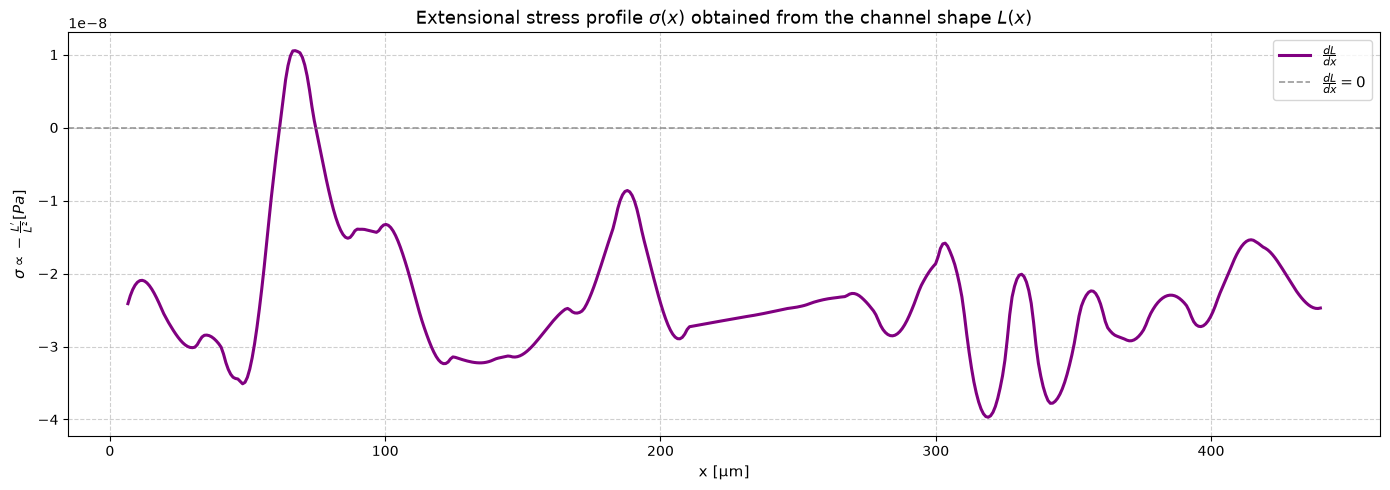

In [ ]:
# 1. Calcolo della derivata numerica dL/dx rispetto a x
q=1
#q = average_width*average_v_x
dL_dx = np.gradient(L_vals, x_vals)
dL_dx_smooth = savgol_filter(dL_dx, window_length=31, polyorder=3)
#stress = -(1 / (L_vals**2)) * dL_dx
stress = -eta*q*(1 / (L_vals**2)) * dL_dx_smooth


# 2. Grafico della derivata
fig, ax = plt.subplots(figsize=(14, 5))

# Curva della derivata
ax.plot(x_vals*pixel_size_um, stress, color="purple", lw=2.2, label=r"$\frac{dL}{dx}$")
ax.axhline(0,color="gray",linestyle="--",alpha=0.8,lw=1.2,label=r"$\frac{dL}{dx} = 0$")

# Formattazione assi e titolo
ax.set_title(
    r"Extensional stress profile $\sigma(x)$ obtained from the channel shape $L(x)$",
    fontsize=13,
)
ax.set_xlabel("x [µm]", fontsize=11)
ax.set_ylabel(r"$\sigma\propto-\frac{L'}{L^2}  [Pa]$", fontsize=11)
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(loc="upper right", fontsize=11)

plt.tight_layout()
plt.show()


<>:39: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:39: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
C:\Users\RHEODLS\AppData\Local\Temp\ipykernel_14624\3215220201.py:39: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  plt.title("Extensional stress profile $\sigma(x)$ on the channel", fontsize=13)


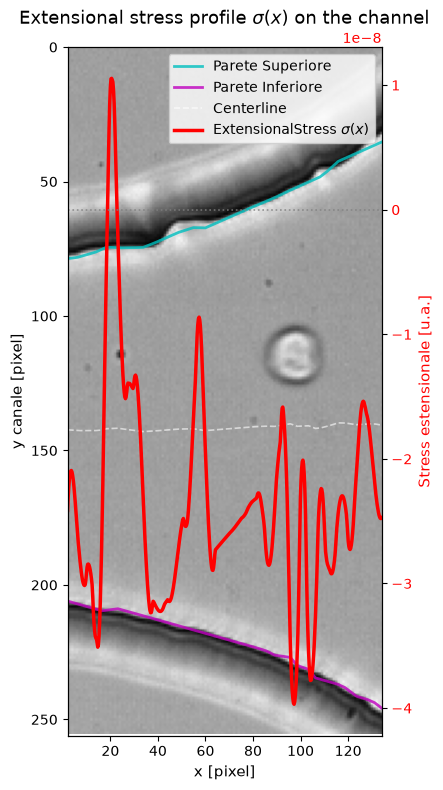

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Dimensioni allungate e schiacciate in y
H, W = cropped.shape
aspect_ratio = W / H
figsize = (8, 8 / aspect_ratio) if aspect_ratio >= 1 else (8 * aspect_ratio, 8)

fig, ax1 = plt.subplots(figsize=figsize)
# 2. Immagine con aspect='auto'
ax1.imshow(cropped, cmap="gray", aspect="auto")
ax1.plot(x_vals, y_t, "-c", lw=2, alpha=0.8, label="Parete Superiore")
ax1.plot(x_vals, y_b, "-m", lw=2, alpha=0.8, label="Parete Inferiore")
ax1.plot(x_vals, y_center, "--w", lw=1.2, alpha=0.6, label="Centerline")

ax1.set_xlabel("x [pixel]", fontsize=11)
ax1.set_ylabel("y canale [pixel]", fontsize=11)
ax1.set_xlim([x_vals.min(), x_vals.max()])
ax1.set_ylim([cropped.shape[0], 0])

# 3. Asse secondario a destra per lo stress in ROSSO
ax2 = ax1.twinx()
ax2.plot(
    x_vals,
    stress,
    color="red",
    lw=2.5,
    label=r"ExtensionalStress $\sigma(x)$",
)
ax2.axhline(0, color="gray", linestyle=":", lw=1.2, alpha=0.8)
ax2.set_ylabel("Stress estensionale [u.a.]", color="red", fontsize=11)
ax2.tick_params(axis="y", labelcolor="red")

# 4. Legende e titolo
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper right")

plt.title("Extensional stress profile $\sigma(x)$ on the channel", fontsize=13)
plt.tight_layout()
plt.show()


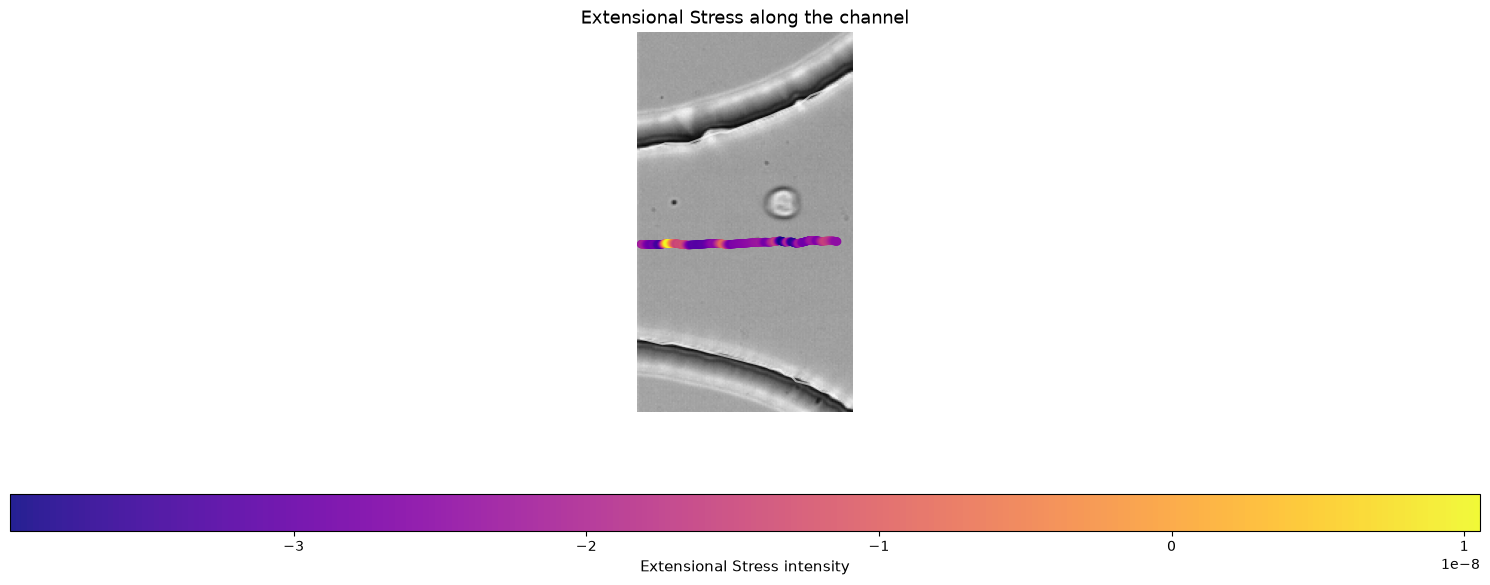

In [8]:
fig, ax = plt.subplots(figsize=(15, 6))

# 1. Immagine di sfondo e bordi
ax.imshow(cropped, cmap="gray")
ax.plot(x_vals, y_t, "-w", lw=1.5, alpha=0.6)
ax.plot(x_vals, y_b, "-w", lw=1.5, alpha=0.6)

# 2. Scatter lungo la linea mediana colorato in base al valore di stress
scatter = ax.scatter(
    x_vals,
    y_center,
    c=stress,
    cmap="plasma",
    s=25,
    alpha=0.9,
    label="Stress lungo la Centerline",
)

# 3. Barra del colore (Colorbar)
cbar = plt.colorbar(scatter, ax=ax, orientation="horizontal", pad=0.15, aspect=40)
cbar.set_label("Extensional Stress intensity", fontsize=11)

ax.set_title("Extensional Stress along the channel", fontsize=13)
ax.axis("off")
plt.tight_layout()
plt.show()
